In [8]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm
import random

from src.data.database import EntityDatabase
from src.embeddings import TextEmbedder, save_embeddings, load_cached_embeddings, get_embedding_cache_info
from src.embeddings import reduce_embeddings_for_visualization

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

## 1. Load Selected Entities

In [9]:
# Load selected entities
entities_file = Path('../data/experiment/selected_entities.csv')
df = pd.read_csv(entities_file)

print(f"✓ Loaded {len(df)} entities")
print(f"\nColumns: {list(df.columns)}")
print(f"\nFirst 3 entities:")
print(df[['id', 'label', 'wikidata_id', 'culture', 'country']].head(3))

✓ Loaded 23007 entities

Columns: ['id', 'wikidata_id', 'type', 'culture', 'country', 'created_at', 'label', 'labels', 'num_wikipedia_languages', 'birth_year', 'occupation_en', 'occupation_fr', 'occupation_ar', 'sex']

First 3 entities:
   id           label wikidata_id  culture        country
0   1  Dwayne Johnson      Q10738  Western  United States
1   2      Mick Foley      Q10731  Western  United States
2   3    Bill Clinton       Q1124  Western  United States


## 2. Connect to Database & Extract Wikipedia Texts

In [10]:
db_path = Path('../data/entities.db')
db = EntityDatabase(db_path)

print(f"✓ Connected to database: {db_path}")

✓ Connected to database: ../data/entities.db


In [11]:
# Extract Wikipedia texts for each language
languages = ['en', 'fr', 'ar']
entity_ids = df['id'].tolist()

# Choose: 'summary' or 'content'
text_type = 'content'  # Change to 'content' for full text (will be truncated at 512 tokens!)

wikipedia_data = {lang: {'entity_ids': [], 'texts': []} for lang in languages}

print(f"Extracting Wikipedia texts ({text_type})...")
for entity_id in tqdm(entity_ids, desc="Processing entities"):
    wiki_texts = db.get_wikipedia_texts(entity_id)

    for lang in languages:
        if lang in wiki_texts and wiki_texts[lang][text_type]:
            wikipedia_data[lang]['entity_ids'].append(entity_id)
            wikipedia_data[lang]['texts'].append(wiki_texts[lang][text_type])

# Show statistics
print("\n" + "="*60)
for lang in languages:
    texts = wikipedia_data[lang]['texts']
    word_counts = [len(text.split()) for text in texts]
    print(f"{lang.upper()}: {len(texts)} texts")
    print(f"  Avg length: {np.mean(word_counts):.0f} words")
    print(f"  Max length: {max(word_counts)} words")
    print(f"  Min length: {min(word_counts)} words")
print("="*60)

# Warning if using full content
if text_type == 'content':
    max_tokens = 512
    print(f"\n⚠️  WARNING: Model max context = {max_tokens} tokens (~384 words)")
    print(f"   Long texts will be truncated. Consider using 'summary' instead.")

Extracting Wikipedia texts (content)...


Processing entities:   0%|          | 0/23007 [00:00<?, ?it/s]


EN: 23007 texts
  Avg length: 1242 words
  Max length: 35170 words
  Min length: 12 words
FR: 23007 texts
  Avg length: 1186 words
  Max length: 93587 words
  Min length: 18 words
AR: 23007 texts
  Avg length: 325 words
  Max length: 27742 words
  Min length: 10 words

⚠️  WARNING: Model max context = 512 tokens (~384 words)
   Long texts will be truncated. Consider using 'summary' instead.


## 4. Wiki data analysis

TEXT LENGTH ANALYSIS - WIKIPEDIA SUMMARIES

## OVERALL STATISTICS BY LANGUAGE ##

EN:
  Count: 23007
  Char length - Median: 3242, Q1: 1292, Q3: 7874
  Est. tokens - Median: 810, Max: 51911
  ⚠️  Truncation risk (>512 tokens): 14599 (63.5%)
  ⚠️  Sparse risk (<200 chars): 241 (1.0%)

FR:
  Count: 23007
  Char length - Median: 2769, Q1: 1177, Q3: 6533
  Est. tokens - Median: 791, Max: 171830
  ⚠️  Truncation risk (>512 tokens): 14654 (63.7%)
  ⚠️  Sparse risk (<200 chars): 38 (0.2%)

AR:
  Count: 23007
  Char length - Median: 581, Q1: 354, Q3: 1382
  Est. tokens - Median: 232, Max: 71640
  ⚠️  Truncation risk (>512 tokens): 6073 (26.4%)
  ⚠️  Sparse risk (<200 chars): 1843 (8.0%)

## DISTRIBUTION BY CULTURE × LANGUAGE (CORE HYPOTHESIS) ##

Median character lengths:

language             ar      en      fr
culture                                
African           432.0  2464.0  2373.0
Arabic           1578.0  1952.0  2306.0
East Asian        434.0  2998.0  2321.0
Latin American    485.0 

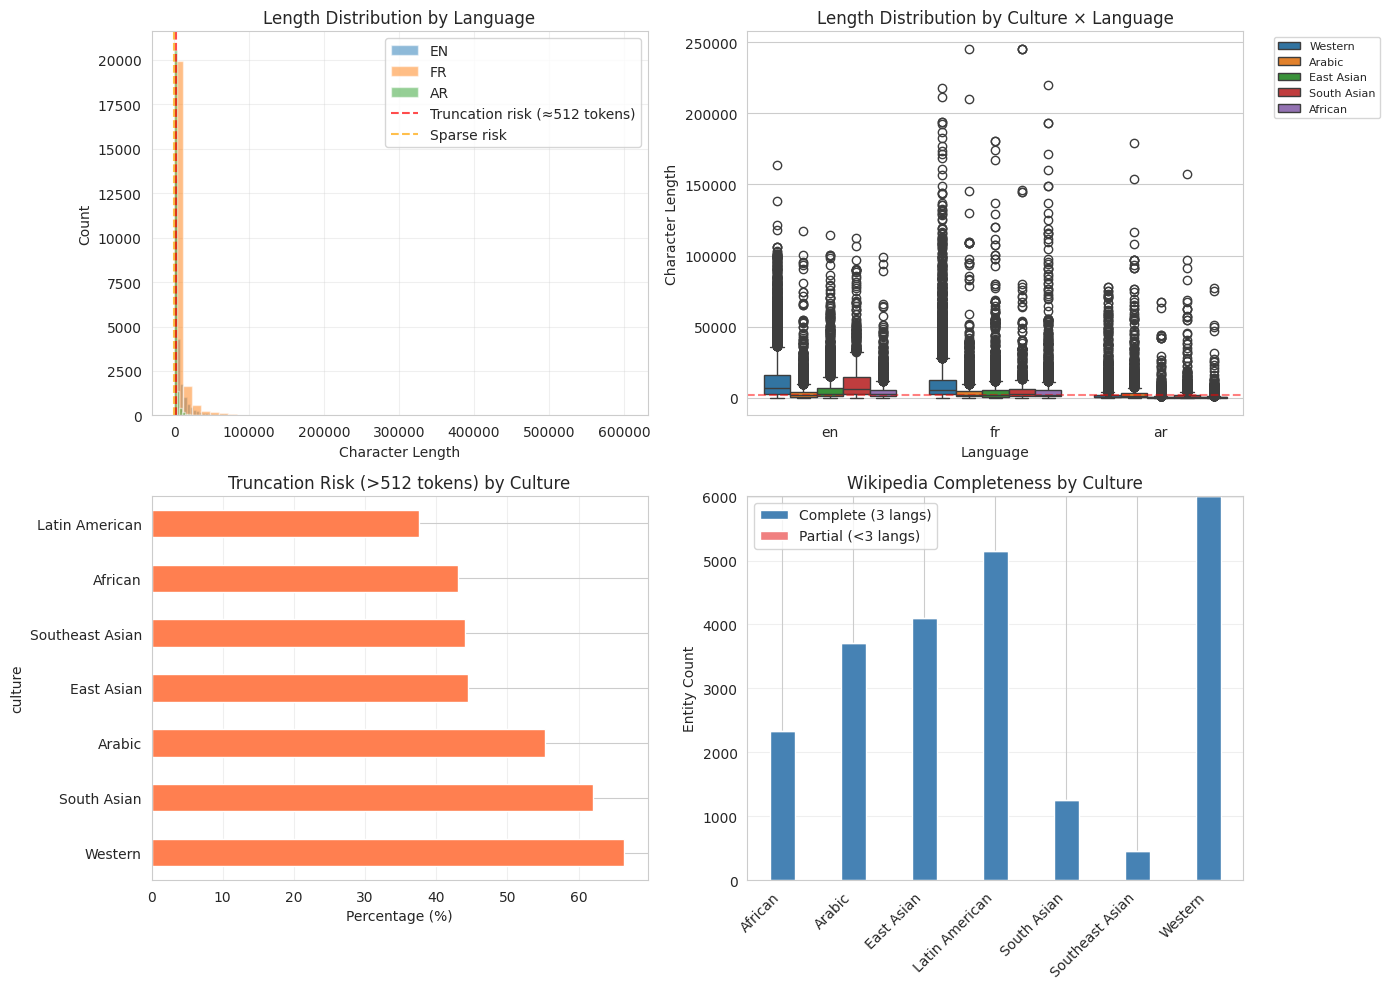


## KEY FINDINGS ##

1. Truncation Risk: 51.2% of summaries exceed 512 tokens
   → Impact: These will lose information during embedding

2. Documentation Gap (entities with all 3 langs):
   → Western entities are 85.3% longer than Arabic entities
   → This supports hypothesis: LLMs trained on Wikipedia will know more about Western entities

3. Cross-language Completeness: 100.0% of entities have all 3 Wikipedia versions
   → Experiment 2 (cross-language comparison) limited to 23007 entities

4. Sparse Texts: 3.1% are <200 chars
   → These may produce poor quality embeddings


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================================
# 1. MERGE CULTURE LABELS WITH WIKIPEDIA DATA
# ============================================================================

# Create lookup: entity_id -> culture
entity_to_culture = df.set_index('id')['culture'].to_dict()
entity_to_country = df.set_index('id')['country'].to_dict()

# Build analysis dataframe
rows = []
for lang in ['en', 'fr', 'ar']:
    for entity_id, text in zip(wikipedia_data[lang]['entity_ids'],
                                 wikipedia_data[lang]['texts']):
        rows.append({
            'entity_id': entity_id,
            'language': lang,
            'text': text,
            'culture': entity_to_culture.get(entity_id, 'Unknown'),
            'country': entity_to_country.get(entity_id, 'Unknown'),
            'char_length': len(text),
            'word_count': len(text.split()),
        })

analysis_df = pd.DataFrame(rows)

# ============================================================================
# 2. CALCULATE ESTIMATED TOKENS (language-specific)
# ============================================================================

# Token estimation: chars per token varies by language
token_ratios = {'en': 4.0, 'fr': 3.5, 'ar': 2.5}  # Conservative estimates

analysis_df['estimated_tokens'] = analysis_df.apply(
    lambda x: x['char_length'] / token_ratios[x['language']], axis=1
).astype(int)

# ============================================================================
# 3. FLAG RISKS
# ============================================================================

analysis_df['truncation_risk'] = analysis_df['estimated_tokens'] > 512
analysis_df['sparse_risk'] = analysis_df['char_length'] < 200

print("="*70)
print("TEXT LENGTH ANALYSIS - WIKIPEDIA SUMMARIES")
print("="*70)

# ============================================================================
# 4. OVERALL STATISTICS BY LANGUAGE
# ============================================================================

print("\n## OVERALL STATISTICS BY LANGUAGE ##\n")

for lang in ['en', 'fr', 'ar']:
    lang_data = analysis_df[analysis_df['language'] == lang]

    print(f"{lang.upper()}:")
    print(f"  Count: {len(lang_data)}")
    print(f"  Char length - Median: {lang_data['char_length'].median():.0f}, "
          f"Q1: {lang_data['char_length'].quantile(0.25):.0f}, "
          f"Q3: {lang_data['char_length'].quantile(0.75):.0f}")
    print(f"  Est. tokens - Median: {lang_data['estimated_tokens'].median():.0f}, "
          f"Max: {lang_data['estimated_tokens'].max():.0f}")
    print(f"  ⚠️  Truncation risk (>512 tokens): {lang_data['truncation_risk'].sum()} "
          f"({100*lang_data['truncation_risk'].mean():.1f}%)")
    print(f"  ⚠️  Sparse risk (<200 chars): {lang_data['sparse_risk'].sum()} "
          f"({100*lang_data['sparse_risk'].mean():.1f}%)")
    print()

# ============================================================================
# 5. DISTRIBUTION BY CULTURE × LANGUAGE (CORE HYPOTHESIS)
# ============================================================================

print("="*70)
print("## DISTRIBUTION BY CULTURE × LANGUAGE (CORE HYPOTHESIS) ##")
print("="*70)
print("\nMedian character lengths:\n")

# Create pivot table
pivot = analysis_df.pivot_table(
    values='char_length',
    index='culture',
    columns='language',
    aggfunc='median'
).round(0)

print(pivot)

print("\nEntity counts per group:\n")
count_pivot = analysis_df.pivot_table(
    values='char_length',
    index='culture',
    columns='language',
    aggfunc='count'
).fillna(0).astype(int)

print(count_pivot)

# ============================================================================
# 6. CROSS-LANGUAGE COMPARISON (Entities with all 3 languages)
# ============================================================================

print("\n" + "="*70)
print("## CROSS-LANGUAGE CONSISTENCY (Entities with all 3 languages) ##")
print("="*70)

# Find entities present in all 3 languages
entity_counts = analysis_df.groupby('entity_id')['language'].nunique()
complete_entities = entity_counts[entity_counts == 3].index.tolist()

complete_df = analysis_df[analysis_df['entity_id'].isin(complete_entities)]

print(f"\nEntities with all 3 languages: {len(complete_entities)}")
print(f"Total texts analyzed: {len(complete_df)}")

# Group by culture for complete entities
print("\nMedian lengths by culture (complete entities only):\n")
complete_pivot = complete_df.pivot_table(
    values='char_length',
    index='culture',
    columns='language',
    aggfunc='median'
).round(0)

print(complete_pivot)

# Statistical test: Do Western entities have longer texts than Arabic entities?
western_complete = complete_df[complete_df['culture'] == 'Western']['char_length']
arabic_complete = complete_df[complete_df['culture'] == 'Arabic']['char_length']

if len(western_complete) > 0 and len(arabic_complete) > 0:
    print(f"\n📊 Western entities (complete): Median = {western_complete.median():.0f} chars")
    print(f"📊 Arabic entities (complete): Median = {arabic_complete.median():.0f} chars")
    print(f"📊 Gap: {western_complete.median() - arabic_complete.median():.0f} chars "
          f"({100*(western_complete.median()/arabic_complete.median() - 1):.1f}% longer)")

# ============================================================================
# 7. VISUALIZATIONS
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Distribution by language
ax = axes[0, 0]
for lang in ['en', 'fr', 'ar']:
    lang_data = analysis_df[analysis_df['language'] == lang]['char_length']
    ax.hist(lang_data, bins=50, alpha=0.5, label=lang.upper())
ax.axvline(2000, color='red', linestyle='--', alpha=0.7, label='Truncation risk (≈512 tokens)')
ax.axvline(200, color='orange', linestyle='--', alpha=0.7, label='Sparse risk')
ax.set_xlabel('Character Length')
ax.set_ylabel('Count')
ax.set_title('Length Distribution by Language')
ax.legend()
ax.grid(alpha=0.3)

# Plot 2: Boxplot by culture × language
ax = axes[0, 1]
# Limit to main cultures for readability
main_cultures = ['Western', 'Arabic', 'East Asian', 'South Asian', 'African']
plot_df = analysis_df[analysis_df['culture'].isin(main_cultures)]
if len(plot_df) > 0:
    sns.boxplot(data=plot_df, x='language', y='char_length', hue='culture', ax=ax)
    ax.axhline(2000, color='red', linestyle='--', alpha=0.5)
    ax.set_ylabel('Character Length')
    ax.set_xlabel('Language')
    ax.set_title('Length Distribution by Culture × Language')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)

# Plot 3: Truncation risk by culture
ax = axes[1, 0]
risk_by_culture = analysis_df.groupby('culture')['truncation_risk'].mean() * 100
risk_by_culture.sort_values(ascending=False).plot(kind='barh', ax=ax, color='coral')
ax.set_xlabel('Percentage (%)')
ax.set_title('Truncation Risk (>512 tokens) by Culture')
ax.grid(axis='x', alpha=0.3)

# Plot 4: Entity counts (complete vs partial)
ax = axes[1, 1]
complete_counts = complete_df.groupby('culture').size() / 3  # Divide by 3 since each entity has 3 languages
all_counts = df.groupby('culture').size()
partial_counts = all_counts - complete_counts

cultures = all_counts.index.tolist()
x = np.arange(len(cultures))
width = 0.35

ax.bar(x, complete_counts, width, label='Complete (3 langs)', color='steelblue')
ax.bar(x, partial_counts, width, bottom=complete_counts, label='Partial (<3 langs)', color='lightcoral')

ax.set_ylabel('Entity Count')
ax.set_title('Wikipedia Completeness by Culture')
ax.set_xticks(x)
ax.set_xticklabels(cultures, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================================
# 8. KEY FINDINGS SUMMARY
# ============================================================================

print("\n" + "="*70)
print("## KEY FINDINGS ##")
print("="*70)

# Finding 1: Truncation risk
overall_truncation = 100 * analysis_df['truncation_risk'].mean()
print(f"\n1. Truncation Risk: {overall_truncation:.1f}% of summaries exceed 512 tokens")
print(f"   → Impact: These will lose information during embedding")

# Finding 2: Culture gap
if len(western_complete) > 0 and len(arabic_complete) > 0:
    gap_pct = 100*(western_complete.median()/arabic_complete.median() - 1)
    print(f"\n2. Documentation Gap (entities with all 3 langs):")
    print(f"   → Western entities are {gap_pct:.1f}% longer than Arabic entities")
    print(f"   → This supports hypothesis: LLMs trained on Wikipedia will know more about Western entities")

# Finding 3: Completeness
complete_pct = 100 * len(complete_entities) / len(df)
print(f"\n3. Cross-language Completeness: {complete_pct:.1f}% of entities have all 3 Wikipedia versions")
print(f"   → Experiment 2 (cross-language comparison) limited to {len(complete_entities)} entities")

# Finding 4: Sparse texts
sparse_pct = 100 * analysis_df['sparse_risk'].mean()
print(f"\n4. Sparse Texts: {sparse_pct:.1f}% are <200 chars")
print(f"   → These may produce poor quality embeddings")

print("="*70)

In [13]:
# Find entities where Arabic text is suspiciously short compared to EN/FR
flgaed_entities = []
for i in range(len(df)):
    entity_id = df.iloc[i]['id']
    entity_name = df.iloc[i]['label']

    # Get texts for this entity
    en_idx = wikipedia_data['en']['entity_ids'].index(entity_id) if entity_id in wikipedia_data['en']['entity_ids'] else None
    ar_idx = wikipedia_data['ar']['entity_ids'].index(entity_id) if entity_id in wikipedia_data['ar']['entity_ids'] else None

    if en_idx and ar_idx:
        en_len = len(wikipedia_data['en']['texts'][en_idx])
        ar_len = len(wikipedia_data['ar']['texts'][ar_idx])

        # Flag if Arabic is <20% of English length
        if ar_len < 0.2 * en_len and ar_len < 300:
            flgaed_entities.append((entity_name, en_len, ar_len, wikipedia_data['ar']['texts'][ar_idx]))
            print(f"{entity_name}: EN={en_len} chars, AR={ar_len} chars")


David DeCoteau: EN=1797 chars, AR=144 chars
Francine Berman: EN=6764 chars, AR=191 chars
Joyce Jacobson Kaufman: EN=1278 chars, AR=218 chars
Justin Gatlin: EN=23598 chars, AR=168 chars
Stan Coveleski: EN=19225 chars, AR=187 chars
Donna Auguste: EN=4942 chars, AR=115 chars
Sandra Lerner: EN=5117 chars, AR=259 chars
Henriette Avram: EN=12162 chars, AR=253 chars
Jane Stafford: EN=3227 chars, AR=215 chars
Pauline Newman: EN=18015 chars, AR=143 chars
Anna Marie Hahn: EN=3396 chars, AR=217 chars
Helen M. Berman: EN=6858 chars, AR=146 chars
Wolfgang Kapp: EN=6388 chars, AR=282 chars
Ming C. Lin: EN=3038 chars, AR=131 chars
Mary Shaw: EN=2807 chars, AR=120 chars
Mária Telkes: EN=16102 chars, AR=221 chars
Dalton Caldwell: EN=1423 chars, AR=136 chars
Anna J. Harrison: EN=4836 chars, AR=262 chars
Hazel Bishop: EN=6405 chars, AR=228 chars
Frank Eugene: EN=4914 chars, AR=202 chars
Joanna S. Fowler: EN=6082 chars, AR=233 chars
Corey Dillon: EN=7105 chars, AR=266 chars
Bill Johnston: EN=35405 chars, 

In [14]:
len(flgaed_entities)

3117

In [15]:
for entity in flgaed_entities[0:20]:
    print(entity)

('David DeCoteau', 1797, 144, 'ديفيد ديكوتو (David DeCoteau) هو منتج ومخرج كندي - أمريكي من مواليد 5 يناير 1962.\n\n\n== أعماله ==\nمن أعماله فيلم غضب الدب الأشيب.\n\n\n== المراجع ==')
('Francine Berman', 6764, 191, 'فرانسينا بيرمان (بالإنجليزية: Francine Berman) هي عَالِمَة حاسوب وأستاذة جامعية أمريكية، ولدت في 7 فبراير 1951 في غلينديل في الولايات المتحدة.\n\n\n== مراجع ==\n\n\n== وصلات خارجية ==\nالموقع الرسمي')
('Joyce Jacobson Kaufman', 1278, 218, 'جويس جاكوبسون كوفمان (بالإنجليزية: Joyce Jacobson Kaufman) (و. 1929 –  م) هي كيميائية، وفيزيائية، وأستاذة جامعية من الولايات المتحدة الأمريكية .\n\n\n== جوائز ==\nحصلت على جوائز منها:\n\nميدالية غارفان أولين \u200f.\n\n\n== مراجع ==')
('Justin Gatlin', 23598, 168, 'جاستن غاتلين (مواليد 10 فبراير 1982) هو عداء أمريكي متخصص في سباقات 60 متر، 100 متر و200 متر.حصل على الميدالية الذهبية في أولمبياد 2004 في سباق 100 متر.\n\n\n== المراجع ==')
('Stan Coveleski', 19225, 187, 'ستان كوفيلسكي (بالإنجليزية: Stan Coveleski) (و. 1889 – 1984 م) هو لاعب 

In [16]:
wikipedia_data.keys()

dict_keys(['en', 'fr', 'ar'])

In [17]:
wikipedia_data.get('fr').get('texts')[0:5]

['Dwayne Johnson ([ˈdweɪn ˈd͡ʒɑnsən]) est un acteur, producteur et catcheur (lutteur professionnel) américano-canadien, né le 2 mai 1972 à Hayward (Californie). Il s\'est d\'abord fait connaître pour son travail à la World Wrestling Entertainment, sous le nom de The Rock, qu\'il a aussi utilisé dans les premières années de sa carrière d\'acteur, avant d\'opter progressivement pour son vrai nom à partir de 2006, parfois en étant crédité avec les deux noms combinés : Dwayne « The Rock » Johnson.\nIssu d\'une famille de lutteurs, il devient lui aussi un catcheur reconnu au sein de la World Wrestling Federation / Entertainment. Sa carrière s\'interrompt en 2004. Il revient cependant à la compétition de février 2011 à avril 2013, puis fait occasionnellement quelques apparitions.\nIl commence vers la fin des années 1990 une carrière d\'acteur à Hollywood, d\'abord en mettant à profit sa notoriété précédente et en utilisant son nom de catcheur. Il accède rapidement aux premiers rôles dans les

In [18]:
wikipedia_data.get('ar').get('texts')[0:5]

['دوين دوغلاس جونسون (بالإنجليزية: Dwayne Douglas Johnson) (من مواليد 2 مايو 1972) والمعروف أيضًا باسمه على الحلبة «ذا روك» (بالإنجليزية: The Rock) (الصخرة) وهو ممثل أمريكي كندي، ومنتج أفلام، ورجل أعمال، ومستثمر، ومصارع محترف متقاعد. كان جونسون مصارعًا محترفًا للاتحاد العالمي للمصارعة (دبليو دبليو إي) لمدة ثماني سنوات قبل أن يتابع مسيرته في التمثيل. حققت أفلامه أكثر من 3.5 مليار دولار في أمريكا الشمالية، وأكثر من 10.5 مليار دولار في جميع أنحاء العالم، مما جعل جونسون واحدًا من أكثر نجوم شباك التذاكر نجاحًا واعلى إيرادات على الإطلاق. كما كان جونسون لاعب كرة قدم أمريكية وكرة قدم كندية سابق.\nكان جونسون لاعب كرة قدم جامعية بجامعة ميامي، حيث فاز مع الجامعة ببطولة وطنية في عام 1991. وكان يتطلع في البداية إلى الحصول على مهنة احترافية في كرة القدم، ودخل في مسودة اتحاد كرة القدم الأمريكية عام 1995، ولكنه لم يكمل. نتيجة لذلك، وقع جونسون مع كالغاري ستامبيدرز في الدوري الاحترافي لكرة القدم الكندية (CFL)، ولكن عُزِل من الفريق في منتصف موسمه الأول. بعد فترة وجيزة، بدأ التدريب كمصارع محترف.\nفي عام 1

In [19]:
wikipedia_data.get('en').get('texts')[0:5]

['Dwayne Douglas Johnson (born May 2, 1972), also known by his ring name "the Rock", is an American actor and professional wrestler. He is signed to WWE, where he performs on a part-time basis. Widely regarded as one of the greatest professional wrestlers of all time, Johnson was integral to the development and success of the World Wrestling Federation (WWF, now WWE) during the Attitude Era. He wrestled for the WWF full-time for eight years before pursuing an acting career. His films have grossed over $11.4 billion worldwide, making him one of the world\'s highest-grossing actors of all time. He is a co-owner of the United Football League, a member of the board of directors of TKO Group Holdings—the parent company of UFC and WWE—and co-founder of Seven Bucks Productions.\nAfter accepting an athletic scholarship to play football at the University of Miami, Johnson was a member of the 1991 national championship team but was largely a backup player. Despite aspirations to play professiona

## 3. Check for Cached Embeddings

In [20]:
cache_dir = Path('../data/embeddings')
cache_dir.mkdir(parents=True, exist_ok=True)

# Check what's already cached
cached_files = get_embedding_cache_info(cache_dir)

if cached_files:
    print(f"Found {len(cached_files)} cached embedding files:")
    for cache_info in cached_files:
        print(f"\n  File: {cache_info['filename']}")
        print(f"  Language: {cache_info['language']}")
        print(f"  Text Type: {cache_info.get('text_type', 'unknown')}")
        print(f"  Model: {cache_info['model_name']}")
        print(f"  Count: {cache_info['num_entities']}")
        print(f"  Shape: {cache_info['shape']}")
else:
    print("No cached embeddings found")

Found 6 cached embedding files:

  File: embeddings_ar_content_intfloat_multilingual-e5-large.pkl
  Language: ar
  Text Type: content
  Model: intfloat/multilingual-e5-large
  Count: 23007
  Shape: (23007, 1024)

  File: embeddings_ar_intfloat_multilingual-e5-large.pkl
  Language: ar
  Text Type: unknown
  Model: intfloat/multilingual-e5-large
  Count: 23007
  Shape: (23007, 1024)

  File: embeddings_en_intfloat_multilingual-e5-large.pkl
  Language: en
  Text Type: unknown
  Model: intfloat/multilingual-e5-large
  Count: 23007
  Shape: (23007, 1024)

  File: embeddings_fr_content_intfloat_multilingual-e5-large.pkl
  Language: fr
  Text Type: content
  Model: intfloat/multilingual-e5-large
  Count: 23007
  Shape: (23007, 1024)

  File: embeddings_fr_intfloat_multilingual-e5-large.pkl
  Language: fr
  Text Type: unknown
  Model: intfloat/multilingual-e5-large
  Count: 23007
  Shape: (23007, 1024)

  File: embeddings_en_content_intfloat_multilingual-e5-large.pkl
  Language: en
  Text Type

## 4. Generate or Load Embeddings

Using model: `intfloat/multilingual-e5-large` (max 512 tokens)

In [21]:
model_name = 'intfloat/multilingual-e5-large'
embeddings = {}

print(f"Model: {model_name}\n")
print(f"Text Type: {text_type}\n")
print("="*60)

for lang in languages:
    print(f"\nProcessing {lang.upper()}...")

    # Try to load cached embeddings
    cached = load_cached_embeddings(
        language=lang,
        model_name=model_name,
        save_dir=cache_dir,
        text_type=text_type
    )

    if cached is not None:
        print(f"  ✓ Loaded from cache")
        embeddings[lang] = {
            'embeddings': cached['embeddings'],
            'entity_ids': cached['entity_ids'],
            'model_name': cached['model_name'],
            'text_type': cached.get('text_type', text_type)
        }
        print(f"  Shape: {cached['embeddings'].shape}")
    else:
        print(f"  Generating embeddings...")

        # Initialize embedder (only when needed)
        if 'embedder' not in locals():
            print(f"  Loading model: {model_name}")
            embedder = TextEmbedder(model_name)
            embedder.load_model()

        # Generate embeddings
        texts = wikipedia_data[lang]['texts']
        emb = embedder.embed_texts(texts, batch_size=32, show_progress=True)

        # Save to cache
        save_embeddings(
            embeddings=emb,
            entity_ids=wikipedia_data[lang]['entity_ids'],
            language=lang,
            model_name=model_name,
            save_dir=cache_dir,
            text_type=text_type,
            metadata={'num_texts': len(texts)}
        )

        embeddings[lang] = {
            'embeddings': emb,
            'entity_ids': wikipedia_data[lang]['entity_ids'],
            'model_name': model_name,
            'text_type': text_type
        }
        print(f"  ✓ Generated and cached")
        print(f"  Shape: {emb.shape}")

print("\n" + "="*60)
print("EMBEDDINGS READY")
print("="*60)

Model: intfloat/multilingual-e5-large

Text Type: content


Processing EN...
  ✓ Loaded from cache
  Shape: (23007, 1024)

Processing FR...
  ✓ Loaded from cache
  Shape: (23007, 1024)

Processing AR...
  ✓ Loaded from cache
  Shape: (23007, 1024)

EMBEDDINGS READY


## 5. Validate Embeddings

In [22]:
# Check embedding properties
print("Embedding Validation:\n")

for lang in languages:
    emb = embeddings[lang]['embeddings']

    print(f"{lang.upper()}:")
    print(f"  Shape: {emb.shape}")
    print(f"  Dtype: {emb.dtype}")
    print(f"  Mean: {emb.mean():.4f}")
    print(f"  Std: {emb.std():.4f}")
    print(f"  Min: {emb.min():.4f}")
    print(f"  Max: {emb.max():.4f}")

    # Check for NaN or Inf
    has_nan = np.isnan(emb).any()
    has_inf = np.isinf(emb).any()
    print(f"  Has NaN: {has_nan}")
    print(f"  Has Inf: {has_inf}")
    print()

Embedding Validation:

EN:
  Shape: (23007, 1024)
  Dtype: float32
  Mean: -0.0008
  Std: 0.0312
  Min: -0.1203
  Max: 0.2271
  Has NaN: False
  Has Inf: False

FR:
  Shape: (23007, 1024)
  Dtype: float32
  Mean: -0.0008
  Std: 0.0312
  Min: -0.1276
  Max: 0.2395
  Has NaN: False
  Has Inf: False

AR:
  Shape: (23007, 1024)
  Dtype: float32
  Mean: -0.0008
  Std: 0.0312
  Min: -0.1256
  Max: 0.2331
  Has NaN: False
  Has Inf: False



In [23]:
# Compute norms
for lang in languages:
    emb = embeddings[lang]['embeddings']
    norms = np.linalg.norm(emb, axis=1)

    print(f"{lang.upper()} - L2 Norms:")
    print(f"  Mean: {norms.mean():.4f}")
    print(f"  Std: {norms.std():.4f}")
    print(f"  Min: {norms.min():.4f}")
    print(f"  Max: {norms.max():.4f}")
    print()

EN - L2 Norms:
  Mean: 1.0000
  Std: 0.0000
  Min: 1.0000
  Max: 1.0000

FR - L2 Norms:
  Mean: 1.0000
  Std: 0.0000
  Min: 1.0000
  Max: 1.0000

AR - L2 Norms:
  Mean: 1.0000
  Std: 0.0000
  Min: 1.0000
  Max: 1.0000



## 6. Visualize Embedding Space (2D)

In [24]:
# Reduce to 2D for visualization
embeddings_2d = {}

print("Reducing embeddings to 2D (UMAP)...")
for lang in languages:
    emb = embeddings[lang]['embeddings']
    emb_2d = reduce_embeddings_for_visualization(emb, method='umap')
    embeddings_2d[lang] = emb_2d
    print(f"  {lang.upper()}: {emb.shape} -> {emb_2d.shape}")

Reducing embeddings to 2D (UMAP)...


/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/numba/np/ufunc/parallel.py:373: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


  EN: (23007, 1024) -> (23007, 2)


/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  FR: (23007, 1024) -> (23007, 2)


/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  AR: (23007, 1024) -> (23007, 2)


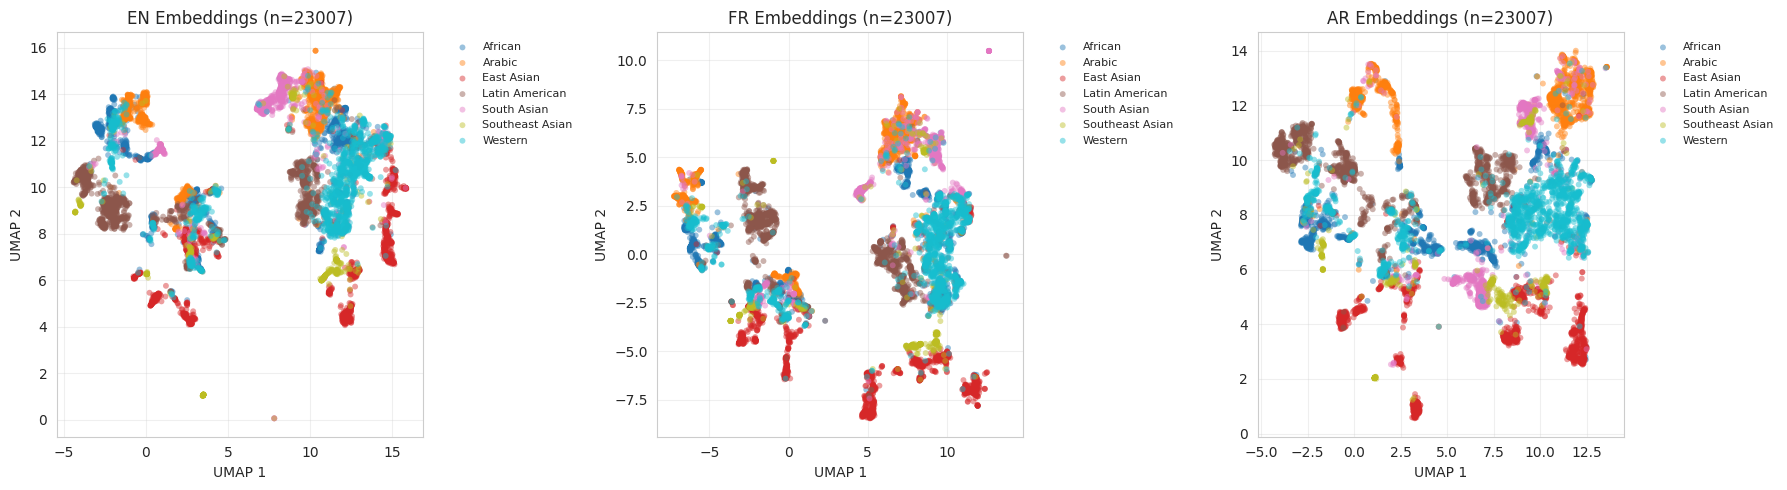

In [77]:
# Plot 2D embeddings for each language (sampled per culture)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
max_per_culture = 1500  # adjust as needed

for i, lang in enumerate(languages):
    ax = axes[i]
    emb_2d = embeddings_2d[lang]

    entity_ids = embeddings[lang]['entity_ids']
    entity_df = df[df['id'].isin(entity_ids)].set_index('id')
    cultures = [entity_df.loc[eid, 'culture'] if eid in entity_df.index else 'Unknown'
                for eid in entity_ids]

    unique_cultures = sorted(set(cultures))
    colors = plt.cm.tab10(np.linspace(0, 1, len(unique_cultures)))

    for culture, color in zip(unique_cultures, colors):
        mask = np.array([c == culture for c in cultures])
        idx = np.where(mask)[0]

        # Sample to limit point count per culture
        if len(idx) > max_per_culture:
            idx = random.sample(list(idx), max_per_culture)

        ax.scatter(emb_2d[idx, 0], emb_2d[idx, 1],
                   c=[color], label=culture, alpha=0.45, s=18, edgecolors='none')

    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    ax.set_title(f'{lang.upper()} Embeddings (n={len(emb_2d)})')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8, frameon=False)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

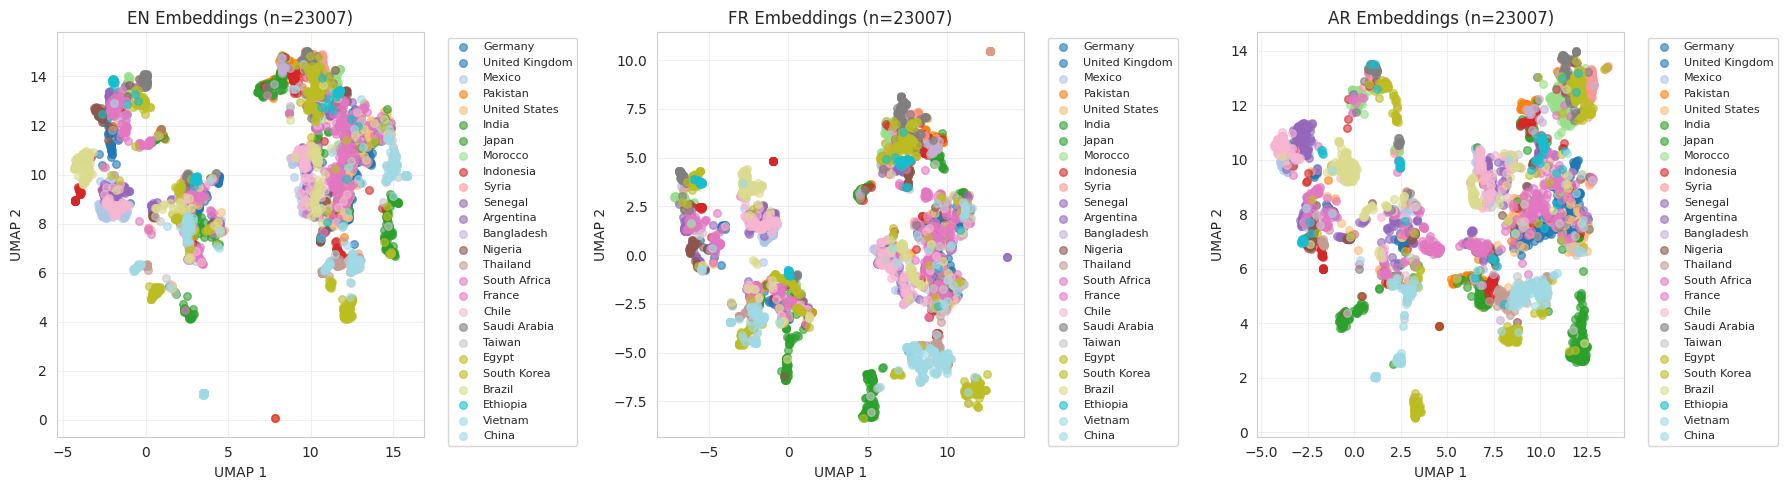

In [73]:


# Plot 2D embeddings for each language
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, lang in enumerate(languages):
    ax = axes[i]
    emb_2d = embeddings_2d[lang]

    # Get entity IDs and map to country
    entity_ids = embeddings[lang]['entity_ids']
    entity_df = df[df['id'].isin(entity_ids)].set_index('id')
    countries = [entity_df.loc[eid, 'country'] if eid in entity_df.index else 'Unknown'
                 for eid in entity_ids]

    # Unique countries and assign colors
    unique_countries = list(set(countries))
    colors = plt.cm.tab20(np.linspace(0, 1, len(unique_countries)))

    for country, color in zip(unique_countries, colors):
        mask = np.array([c == country for c in countries])
        indices = np.where(mask)[0]

        # Sample up to 200 per country
        if len(indices) > 200:
            indices = random.sample(list(indices), 200)

        ax.scatter(emb_2d[indices, 0], emb_2d[indices, 1],
                   c=[color], label=country, alpha=0.6, s=30)

    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    ax.set_title(f'{lang.upper()} Embeddings (n={len(emb_2d)})')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Visualize Enriched Metadata

Visualize occupation groups, Wikipedia language coverage, and birth year distributions

In [62]:
def group_occupation(occupation):
    """
    Group specific occupations into broader categories for visualization.

    Args:
        occupation: Specific occupation string (e.g., 'actor', 'basketball player')

    Returns:
        str: Broad category (e.g., 'Arts & Entertainment', 'Sports')
    """
    if pd.isna(occupation):
        return 'Unknown'

    occupation = str(occupation).lower()

    # Sports
    sports_keywords = ['player', 'athlete', 'coach', 'runner', 'swimmer', 'cyclist',
                       'boxer', 'wrestler', 'golfer', 'tennis', 'football', 'basketball',
                       'baseball', 'hockey', 'racing', 'driver', 'gymnast', 'skier',
                       'jumper', 'thrower', 'judoka', 'karateka', 'martial', 'olymp']
    if any(kw in occupation for kw in sports_keywords):
        return 'Sports'

    # Arts & Entertainment
    arts_keywords = ['actor', 'singer', 'musician', 'artist', 'painter', 'dancer',
                     'composer', 'writer', 'author', 'poet', 'novelist', 'playwright',
                     'director', 'producer', 'photographer', 'animator', 'comedian',
                     'entertainer', 'model', 'designer', 'sculptor', 'illustrator',
                     'guitarist', 'drummer', 'pianist', 'conductor', 'rapper']
    if any(kw in occupation for kw in arts_keywords):
        return 'Arts & Entertainment'

    # Science & Academia
    science_keywords = ['scientist', 'physicist', 'chemist', 'biologist', 'researcher',
                        'professor', 'teacher', 'academic', 'mathematician', 'astronomer',
                        'engineer', 'inventor', 'geologist', 'botanist', 'zoologist',
                        'archaeologist', 'historian', 'psychologist', 'physician',
                        'surgeon', 'doctor', 'pharmacist', 'nurse', 'medical']
    if any(kw in occupation for kw in science_keywords):
        return 'Science & Academia'

    # Politics & Law
    politics_keywords = ['politician', 'minister', 'governor', 'senator', 'president',
                         'lawyer', 'judge', 'diplomat', 'ambassador', 'activist',
                         'jurist', 'statesperson', 'official', 'legislator']
    if any(kw in occupation for kw in politics_keywords):
        return 'Politics & Law'

    # Business & Finance
    business_keywords = ['business', 'entrepreneur', 'executive', 'banker', 'manager',
                         'investor', 'financier', 'industrialist', 'merchant']
    if any(kw in occupation for kw in business_keywords):
        return 'Business & Finance'

    # Religious
    religious_keywords = ['priest', 'bishop', 'rabbi', 'imam', 'minister', 'monk',
                          'nun', 'clergy', 'religious', 'missionary', 'pastor',
                          'archbishop', 'patriarch', 'mufti', 'ulema']
    if any(kw in occupation for kw in religious_keywords):
        return 'Religious'

    # Military
    military_keywords = ['military', 'soldier', 'officer', 'general', 'commander',
                         'pilot', 'aviator', 'navy', 'army', 'marine']
    if any(kw in occupation for kw in military_keywords):
        return 'Military'

    # Media & Journalism
    media_keywords = ['journalist', 'reporter', 'editor', 'presenter', 'broadcaster',
                      'columnist', 'correspondent', 'blogger', 'youtuber']
    if any(kw in occupation for kw in media_keywords):
        return 'Media & Journalism'

    return 'Other'


# Apply grouping to dataframe
df['occupation_group'] = df['occupation_en'].apply(group_occupation)

# Show distribution
print("Occupation groups distribution:")
print(df['occupation_group'].value_counts())
print(f"\nTotal unique specific occupations: {df['occupation_en'].nunique()}")
print(f"Grouped into: {df['occupation_group'].nunique()} categories")

Occupation groups distribution:
occupation_group
Sports                  9116
Arts & Entertainment    6214
Politics & Law          2482
Other                   2304
Science & Academia      1633
Media & Journalism       484
Business & Finance       331
Military                 291
Religious                152
Name: count, dtype: int64

Total unique specific occupations: 647
Grouped into: 9 categories


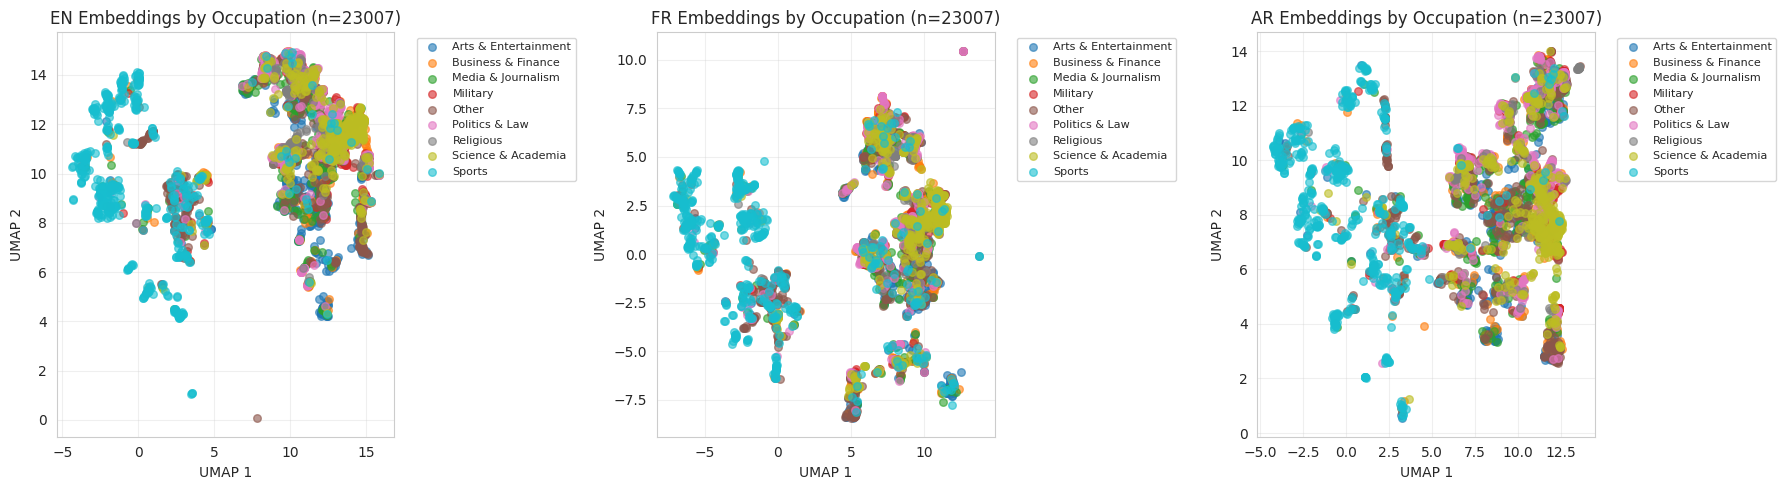

In [78]:
# Visualize embeddings colored by occupation group
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, lang in enumerate(languages):
    ax = axes[i]
    emb_2d = embeddings_2d[lang]

    # Get entity IDs and map to occupation group
    entity_ids = embeddings[lang]['entity_ids']
    entity_df = df[df['id'].isin(entity_ids)].set_index('id')
    occupation_groups = [entity_df.loc[eid, 'occupation_group'] if eid in entity_df.index else 'Unknown'
                         for eid in entity_ids]

    # Unique groups and assign colors
    unique_groups = sorted(list(set(occupation_groups)))
    colors = plt.cm.tab10(np.linspace(0, 1, len(unique_groups)))

    for group, color in zip(unique_groups, colors):
        mask = np.array([g == group for g in occupation_groups])
        indices = np.where(mask)[0]

        # Sample up to 300 per group for visibility
        if len(indices) > 500:
            indices = random.sample(list(indices), 500)

        ax.scatter(emb_2d[indices, 0], emb_2d[indices, 1],
                   c=[color], label=group, alpha=0.6, s=30)

    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    ax.set_title(f'{lang.upper()} Embeddings by Occupation (n={len(emb_2d)})')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

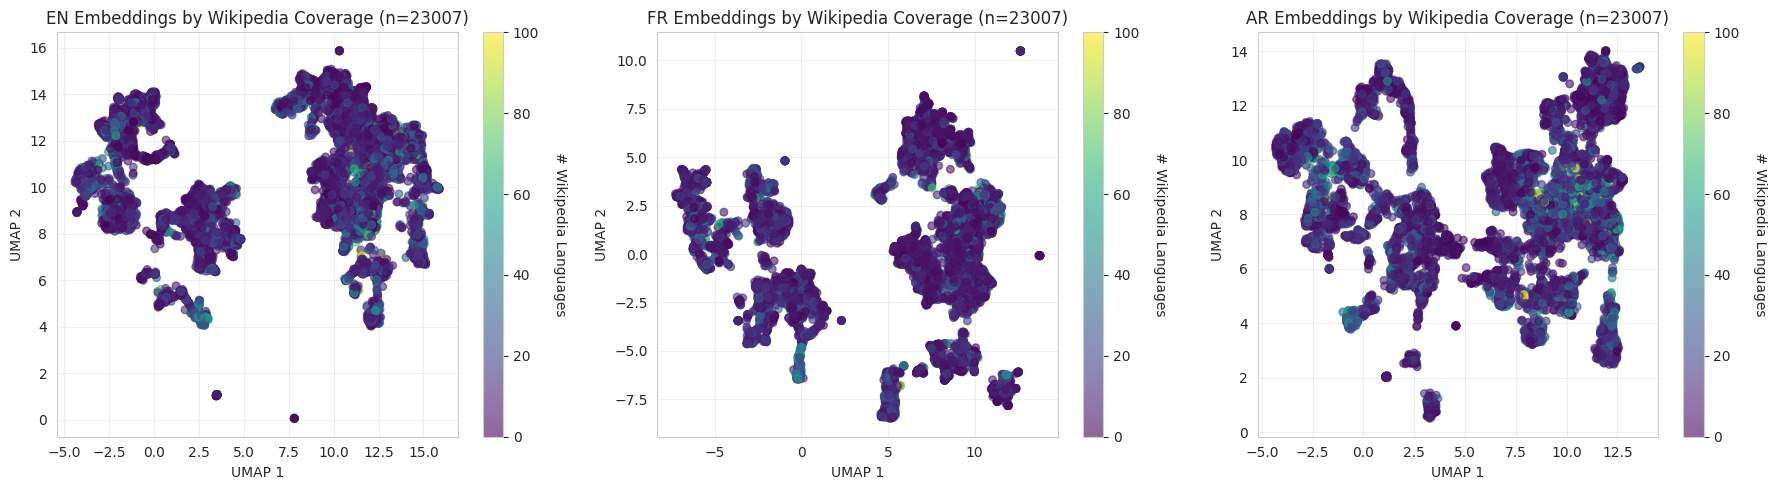


Wikipedia language coverage statistics:
EN: mean=20.9, median=15, min=0, max=280
FR: mean=20.9, median=15, min=0, max=280
AR: mean=20.9, median=15, min=0, max=280


In [64]:
# Visualize embeddings with Wikipedia language coverage heatmap
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, lang in enumerate(languages):
    ax = axes[i]
    emb_2d = embeddings_2d[lang]

    # Get entity IDs and map to Wikipedia language count
    entity_ids = embeddings[lang]['entity_ids']
    entity_df = df[df['id'].isin(entity_ids)].set_index('id')
    wiki_langs = [entity_df.loc[eid, 'num_wikipedia_languages'] if eid in entity_df.index else 0
                  for eid in entity_ids]

    # Convert to numeric, handling string values
    wiki_langs = [int(float(w)) if pd.notna(w) and w != '' else 0 for w in wiki_langs]

    # Create scatter with continuous colormap
    scatter = ax.scatter(emb_2d[:, 0], emb_2d[:, 1],
                        c=wiki_langs, cmap='viridis',
                        alpha=0.6, s=30, vmin=0, vmax=100)

    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label('# Wikipedia Languages', rotation=270, labelpad=20)

    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    ax.set_title(f'{lang.upper()} Embeddings by Wikipedia Coverage (n={len(emb_2d)})')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Print statistics
print("\nWikipedia language coverage statistics:")
for lang in languages:
    entity_ids = embeddings[lang]['entity_ids']
    entity_df = df[df['id'].isin(entity_ids)].set_index('id')
    wiki_langs = [entity_df.loc[eid, 'num_wikipedia_languages'] if eid in entity_df.index else 0
                  for eid in entity_ids]
    wiki_langs = [int(float(w)) if pd.notna(w) and w != '' else 0 for w in wiki_langs]

    print(f"{lang.upper()}: mean={np.mean(wiki_langs):.1f}, median={np.median(wiki_langs):.0f}, "
          f"min={np.min(wiki_langs)}, max={np.max(wiki_langs)}")

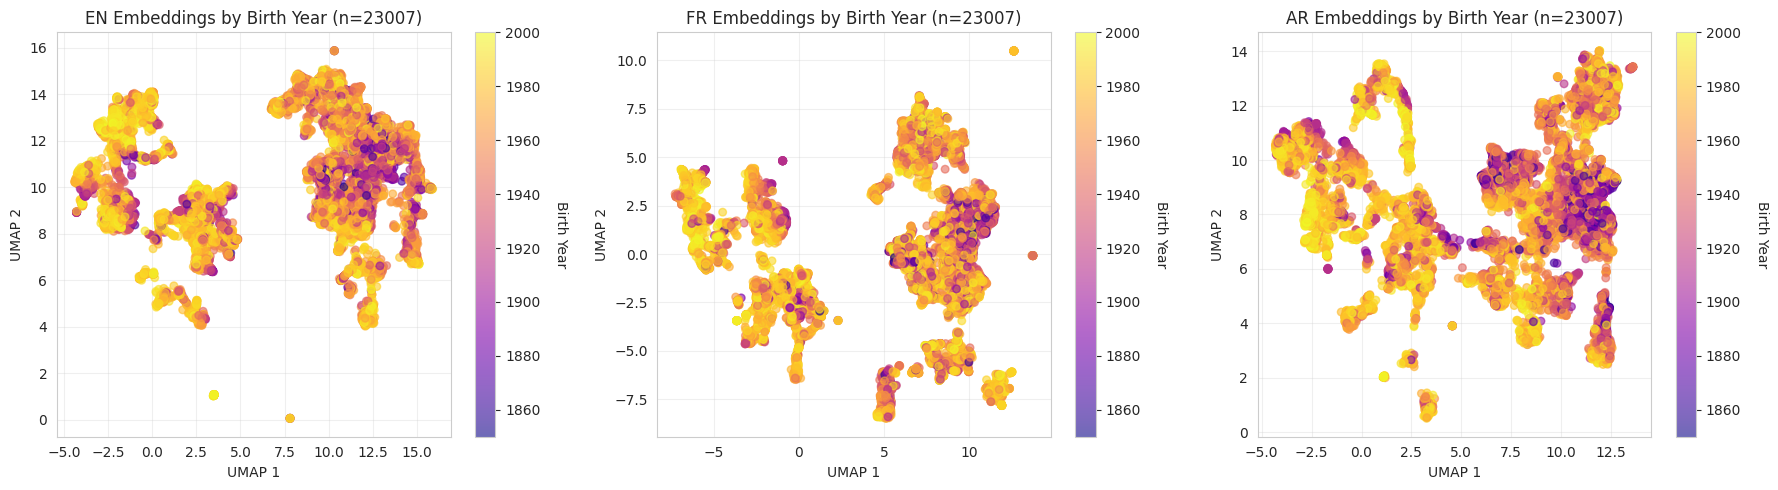


Birth year statistics:
EN: mean=1956, median=1966, min=1851, max=1999, coverage=23007/23007 (100.0%)
FR: mean=1956, median=1966, min=1851, max=1999, coverage=23007/23007 (100.0%)
AR: mean=1956, median=1966, min=1851, max=1999, coverage=23007/23007 (100.0%)


In [ ]:
# Visualize embeddings with birth year heatmap
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, lang in enumerate(languages):
    ax = axes[i]
    emb_2d = embeddings_2d[lang]

    # Get entity IDs and map to birth year
    entity_ids = embeddings[lang]['entity_ids']
    entity_df = df[df['id'].isin(entity_ids)].set_index('id')
    birth_years = [entity_df.loc[eid, 'birth_year'] if eid in entity_df.index else np.nan
                   for eid in entity_ids]

    # Convert to numeric, handling string and missing values
    birth_years = [int(float(y)) if pd.notna(y) and str(y) != '' and str(y) != 'nan' else np.nan
                   for y in birth_years]

    # Filter out NaN values for plotting
    valid_mask = ~np.isnan(birth_years)
    valid_emb = emb_2d[valid_mask]
    valid_years = np.array(birth_years)[valid_mask]

    # Create scatter with continuous colormap
    if len(valid_years) > 0:
        scatter = ax.scatter(valid_emb[:, 0], valid_emb[:, 1],
                            c=valid_years, cmap='plasma',
                            alpha=0.6, s=30, vmin=1850, vmax=2000)

        # Add colorbar
        cbar = plt.colorbar(scatter, ax=ax)
        cbar.set_label('Birth Year', rotation=270, labelpad=20)

    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    ax.set_title(f'{lang.upper()} Embeddings by Birth Year (n={len(valid_emb)})')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Print statistics
print("\nBirth year statistics:")
for lang in languages:
    entity_ids = embeddings[lang]['entity_ids']
    entity_df = df[df['id'].isin(entity_ids)].set_index('id')
    birth_years = [entity_df.loc[eid, 'birth_year'] if eid in entity_df.index else np.nan
                   for eid in entity_ids]
    birth_years = [int(float(y)) if pd.notna(y) and str(y) != '' and str(y) != 'nan' else np.nan
                   for y in birth_years]
    valid_years = [y for y in birth_years if not np.isnan(y)]

    if len(valid_years) > 0:
        print(f"{lang.upper()}: mean={np.mean(valid_years):.0f}, median={np.median(valid_years):.0f}, "
              f"min={int(np.min(valid_years))}, max={int(np.max(valid_years))}, "
              f"coverage={len(valid_years)}/{len(birth_years)} ({100*len(valid_years)/len(birth_years):.1f}%)")
    else:
        print(f"{lang.upper()}: No valid birth years found")

In [ ]:
# Visualize embeddings colored by sex/gender
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, lang in enumerate(languages):
    ax = axes[i]
    emb_2d = embeddings_2d[lang]

    # Get entity IDs and map to sex
    entity_ids = embeddings[lang]['entity_ids']
    entity_df = df[df['id'].isin(entity_ids)].set_index('id')
    sexes = [entity_df.loc[eid, 'sex'] if eid in entity_df.index else 'Unknown'
             for eid in entity_ids]

    # Handle NaN values - convert to 'Unknown'
    sexes = [s if pd.notna(s) else 'Unknown' for s in sexes]

    # Define colors for each sex
    sex_colors = {'male': 'blue', 'female': 'red', 'Unknown': 'gray'}
    unique_sexes = sorted(list(set(sexes)))

    for sex in unique_sexes:
        mask = np.array([s == sex for s in sexes])
        indices = np.where(mask)[0]

        color = sex_colors.get(sex, 'gray')
        ax.scatter(emb_2d[indices, 0], emb_2d[indices, 1],
                   c=color, label=sex, alpha=0.6, s=30)

    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    ax.set_title(f'{lang.upper()} Embeddings by Gender (n={len(emb_2d)})')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Print statistics
print("\nGender distribution:")
for lang in languages:
    entity_ids = embeddings[lang]['entity_ids']
    entity_df = df[df['id'].isin(entity_ids)].set_index('id')
    sexes = [entity_df.loc[eid, 'sex'] if eid in entity_df.index else 'Unknown'
             for eid in entity_ids]

    # Handle NaN values
    sexes = [s if pd.notna(s) else 'Unknown' for s in sexes]

    from collections import Counter
    sex_counts = Counter(sexes)
    print(f"\n{lang.upper()}:")
    for sex, count in sorted(sex_counts.items(), key=lambda x: -x[1]):
        pct = 100 * count / len(sexes)
        print(f"  {sex}: {count} ({pct:.1f}%)")

In [68]:
df

,id,wikidata_id,type,culture,country,created_at,label,labels,num_wikipedia_languages,birth_year,occupation_en,occupation_fr,occupation_ar,sex,occupation_group
0,1,Q10738,person,Western,United States,2025-12-17 00:26:11,Dwayne Johnson,"{'ar': 'دوين جونسون', 'en': 'Dwayne Johnson', ...",102,1972.0,Canadian football player,joueur de football canadien,لاعب كرة قدم كندية,male,Sports
1,2,Q10731,person,Western,United States,2025-12-17 00:26:19,Mick Foley,"{'ar': 'ميك فولي', 'en': 'Mick Foley', 'fr': '...",36,1965.0,writer,écrivain ou écrivaine,كاتب,male,Arts & Entertainment
2,3,Q1124,person,Western,United States,2025-12-17 00:26:23,Bill Clinton,"{'ar': 'بيل كلينتون', 'en': 'Bill Clinton', 'f...",174,1946.0,lawyer,avocat ou avocate,محام,male,Politics & Law
3,4,Q1744,person,Western,United States,2025-12-17 00:26:28,Madonna,"{'ar': 'مادونا', 'en': 'Madonna', 'fr': 'Madon...",154,1958.0,actor,acteur ou actrice,ممثل,female,Arts & Entertainment
4,5,Q4349,person,Western,United States,2025-12-17 00:26:33,Jimmy Bennett,"{'ar': 'جيمي بينيت', 'en': 'Jimmy Bennett', 'f...",30,1996.0,actor,acteur ou actrice,ممثل,male,Arts & Entertainment
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23002,37245,Q18127720,person,Latin American,Chile,2026-01-01 10:10:34,Rodrigo Salinas Muñoz,"{'ar': 'رودريجو ساليناس مونيوز', 'en': 'Rodrig...",11,1989.0,handball player,handballeur ou handballeuse,لاعب كرة يد,male,Sports
23003,37246,Q6524166,person,Latin American,Chile,2026-01-01 10:10:34,Leo Rey,"{'ar': 'ليو ري', 'en': 'Leo Rey', 'fr': 'Leo R...",6,1979.0,singer,chanteur ou chanteuse,مغني,male,Arts & Entertainment
23004,37247,Q6968078,person,Latin American,Chile,2026-01-01 10:10:34,Natalia Romero,"{'ar': 'ناتاليا روميرو', 'en': 'Natalia Romero...",12,1980.0,athletics competitor,athlète,منافس ألعاب قوى,female,Other
23005,37252,Q106904381,person,Latin American,Chile,2026-01-01 10:10:34,Elisa Loncon,"{'ar': 'إليسا لونكون', 'en': 'Elisa Loncon', '...",17,1963.0,politician,personnalité politique,سياسي,female,Politics & Law


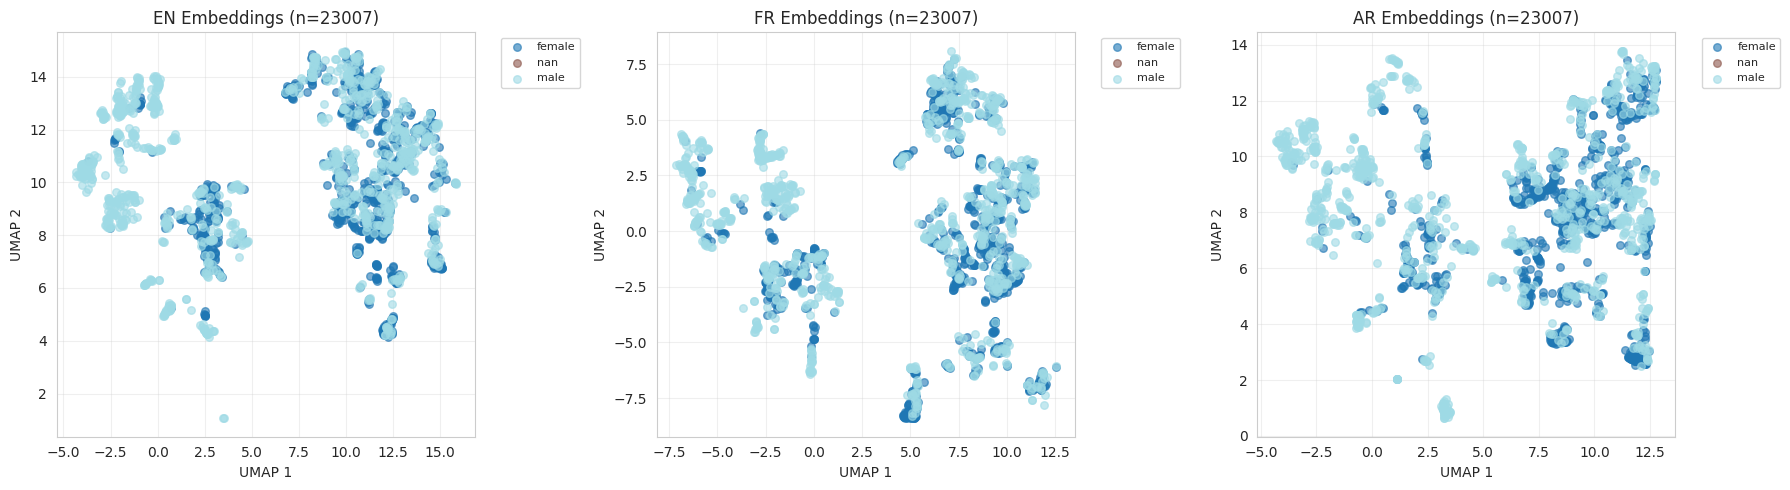

In [69]:
# Plot 2D embeddings for each language
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, lang in enumerate(languages):
    ax = axes[i]
    emb_2d = embeddings_2d[lang]

    # Get entity IDs and map to country
    entity_ids = embeddings[lang]['entity_ids']
    entity_df = df[df['id'].isin(entity_ids)].set_index('id')
    countries = [entity_df.loc[eid, 'sex'] if eid in entity_df.index else 'Unknown'
                 for eid in entity_ids]

    # Unique countries and assign colors
    unique_countries = list(set(countries))
    colors = plt.cm.tab20(np.linspace(0, 1, len(unique_countries)))

    for country, color in zip(unique_countries, colors):
        mask = np.array([c == country for c in countries])
        indices = np.where(mask)[0]

        # Sample up to 200 per country
        if len(indices) > 5000:
            indices = random.sample(list(indices), 1000)

        ax.scatter(emb_2d[indices, 0], emb_2d[indices, 1],
                   c=[color], label=country, alpha=0.6, s=30)

    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    ax.set_title(f'{lang.upper()} Embeddings (n={len(emb_2d)})')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Compare Languages

Plot all languages together to see if they cluster

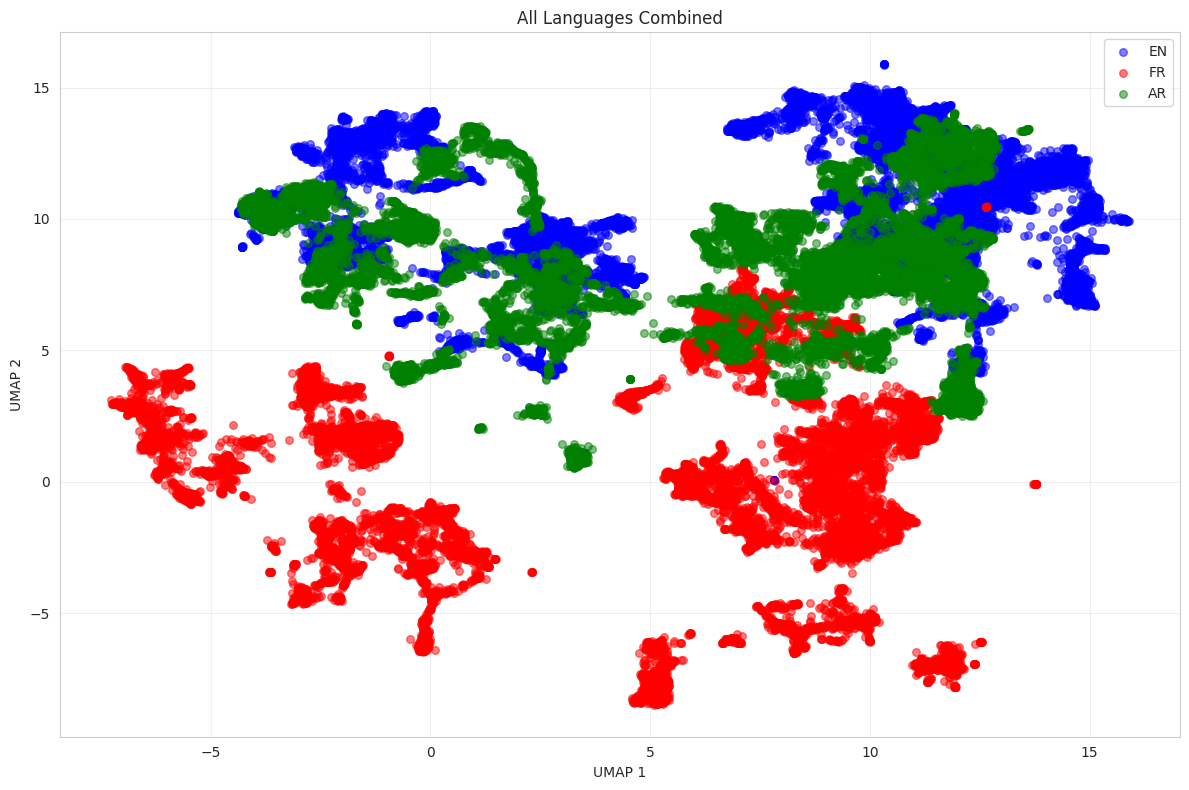

In [20]:
# Combine all embeddings for visualization
all_embeddings = []
all_labels = []

for lang in languages:
    emb_2d = embeddings_2d[lang]
    all_embeddings.append(emb_2d)
    all_labels.extend([lang] * len(emb_2d))

all_embeddings = np.vstack(all_embeddings)

# Plot
fig, ax = plt.subplots(figsize=(12, 8))

lang_colors = {'en': 'blue', 'fr': 'red', 'ar': 'green'}
for lang in languages:
    mask = np.array([l == lang for l in all_labels])
    ax.scatter(all_embeddings[mask, 0], all_embeddings[mask, 1],
              c=lang_colors[lang], label=lang.upper(), alpha=0.5, s=30)

ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
ax.set_title('All Languages Combined')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Compute Similarity Statistics

In [21]:
# Find entities that exist in all languages
common_entity_ids = set(embeddings['en']['entity_ids'])
for lang in languages[1:]:
    common_entity_ids = common_entity_ids.intersection(set(embeddings[lang]['entity_ids']))

common_entity_ids = sorted(list(common_entity_ids))

print(f"Entities with embeddings in all languages: {len(common_entity_ids)}")

Entities with embeddings in all languages: 23007


In [22]:
# For common entities, compute cross-language similarities
if len(common_entity_ids) > 0:
    # Get embeddings for common entities in each language
    common_embeddings = {}

    for lang in languages:
        entity_ids = embeddings[lang]['entity_ids']
        emb = embeddings[lang]['embeddings']

        # Find indices of common entities
        indices = [entity_ids.index(eid) for eid in common_entity_ids if eid in entity_ids]
        common_embeddings[lang] = emb[indices]

        print(f"{lang}: {len(indices)} common entities")

    # Compute pairwise similarities
    from sklearn.metrics.pairwise import cosine_similarity

    print("\n" + "="*60)
    print("Cross-Language Similarities (mean cosine similarity)")
    print("="*60)

    for i, lang1 in enumerate(languages):
        for lang2 in languages[i+1:]:
            # Compute pairwise similarities for same entities across languages
            similarities = []
            for idx in range(len(common_entity_ids)):
                sim = cosine_similarity(
                    common_embeddings[lang1][idx:idx+1],
                    common_embeddings[lang2][idx:idx+1]
                )[0, 0]
                similarities.append(sim)

            mean_sim = np.mean(similarities)
            std_sim = np.std(similarities)
            print(f"{lang1.upper()} <-> {lang2.upper()}: {mean_sim:.4f} ± {std_sim:.4f}")

en: 23007 common entities
fr: 23007 common entities
ar: 23007 common entities

Cross-Language Similarities (mean cosine similarity)
EN <-> FR: 0.8975 ± 0.0425
EN <-> AR: 0.8586 ± 0.0312
FR <-> AR: 0.8689 ± 0.0362


## 9. Summary Statistics

In [23]:
print("=" * 60)
print("EMBEDDING GENERATION SUMMARY")
print("=" * 60)

print(f"\nModel: {model_name}")
print(f"Total entities: {len(df)}")

print(f"\nEmbeddings generated:")
for lang in languages:
    n_emb = len(embeddings[lang]['entity_ids'])
    dim = embeddings[lang]['embeddings'].shape[1]
    print(f"  {lang.upper()}: {n_emb} entities × {dim} dimensions")

print(f"\nCache directory: {cache_dir}")
print(f"Cached files: {len(list(cache_dir.glob('*.pkl')))}")

print(f"\n✓ Ready for dimension reduction & clustering (notebook 03)")
print("=" * 60)

EMBEDDING GENERATION SUMMARY

Model: intfloat/multilingual-e5-large
Total entities: 23007

Embeddings generated:
  EN: 23007 entities × 1024 dimensions
  FR: 23007 entities × 1024 dimensions
  AR: 23007 entities × 1024 dimensions

Cache directory: ../data/embeddings
Cached files: 6

✓ Ready for dimension reduction & clustering (notebook 03)


In [24]:
# Close database
db.conn.close()
print("Database connection closed")

Database connection closed
